<a href="https://colab.research.google.com/github/Bunkhuoch-Ann/Side_Quests_simple/blob/main/Integral_equation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import wofz, expn
from scipy.interpolate import PchipInterpolator

In [2]:
def trapezoid_weights(x):
    """Weights for the composite trapezoid rule on an increasing grid."""
    w = np.empty_like(x)
    w[0] = 0.5 * (x[1] - x[0])
    w[-1] = 0.5 * (x[-1] - x[-2])
    w[1:-1] = 0.5 * (x[2:] - x[:-2])
    return w

def make_profile(a, tau_max, nfreq=10001):
    """
    Return dimensionless profile phi(x) and frequency-integration weights.
    Uses the standard Voigt function H(a,x) = Re[w(x + i a)].
    For a=0, this is the Doppler profile exp(-x^2).
    """
    if a == 0:
        xmax = 9.0
    else:
        # Include the far wings relevant at the largest optical depths.
        xmax = max(12.0, 8.0 * np.sqrt(a * tau_max))
    # A sinh grid resolves the line core and extends into the far wings.
    umax = np.arcsinh(xmax)
    u = np.linspace(-umax, umax, nfreq)
    x = np.sinh(u)
    H = np.real(wofz(x + 1j * a))
    H0 = np.real(wofz(1j * a))  # line-center value
    phi = H / H0
    # The frequency measure in the slide is dx = varphi_nu0 dnu.
    # In Doppler coordinates this is H0/sqrt(pi) times dx.
    wx = trapezoid_weights(x)
    freq_weights = (H0 / np.sqrt(np.pi)) * wx
    # Renormalize for the finite numerical frequency interval.
    freq_weights /= np.sum(phi * freq_weights)
    return phi, freq_weights


def make_F_interpolator(a, tau_max, min_s, n_s=1400, nfreq=10001):
    """
    Build F(s) = integral_0^s K1(s') ds' = [1 - K2(s)]/2.
    Computing F from K2 avoids directly evaluating the logarithmic
    K1(0) singularity.
    """
    phi, freq_weights = make_profile(a, tau_max, nfreq=nfreq)
    s_grid = np.geomspace(min_s, 2.0 * tau_max, n_s)
    K2 = np.empty_like(s_grid)
    # Evaluate in chunks to limit temporary-array memory use.
    chunk_size = 20

    for start in range(0, n_s, chunk_size):
        stop = min(start + chunk_size, n_s)
        z = s_grid[start:stop, None] * phi[None, :]
        K2[start:stop] = np.sum(
            expn(2, z) * phi[None, :] * freq_weights[None, :],
            axis=1,
        )
    # Enforce the exact normalization K2(0)=1 against tiny quadrature errors.
    K2 /= K2[0] if s_grid[0] == 0 else 1.0 #boundary at s=0
    F_grid = 0.5 * (1.0 - K2)
    F_interp = PchipInterpolator(np.log(s_grid), F_grid, extrapolate=True)

    def F(s):
        """Evaluate F(s), with F(0)=0."""
        s = np.asarray(s, dtype=float)
        out = np.zeros_like(s)
        positive = s > 0
        out[positive] = F_interp(np.log(s[positive]))
        return out

    def K2_of_s(s):
        """Evaluate K2(s) using K2=1-2F."""
        s = np.asarray(s, dtype=float)
        return 1.0 - 2.0 * F(s)
    return F, K2_of_s

def build_lambda_matrix(edges, centers, F):
    n = len(centers)
    Lambda = np.zeros((n, n))

    for i, tau_i in enumerate(centers):
        left = edges[:-1]
        right = edges[1:]

        # Cells entirely to the left of tau_i
        left_cells = right <= tau_i
        Lambda[i, left_cells] = (
            F(tau_i - left[left_cells])
            - F(tau_i - right[left_cells])
        )
        # Cells entirely to the right of tau_i
        right_cells = left >= tau_i
        Lambda[i, right_cells] = (
            F(right[right_cells] - tau_i)
            - F(left[right_cells] - tau_i)
        )
        # The cell containing tau_i
        crossing = ~(left_cells | right_cells)
        Lambda[i, crossing] = (
            F(tau_i - left[crossing])
            + F(right[crossing] - tau_i)
        )
    return Lambda


def solve_source_function(epsilon, a, B=1.0, tmin=1e-8,
                          points_per_decade=28, nfreq=10001,
                          tolerance=1e-8, max_iterations=50000):

    """
    Solve the semi-infinite two-level-atom source-function equation
    using diagonal ALI.
    Beyond tau_max, the source is approximated by its thermalized value B.
    """

    # Choose the bottom boundary well beyond the expected thermalization region.
    if a == 0:
        tau_max = 50.0 / epsilon

    else:
        tau_max = max(100.0, 30.0 * 8.0 * a / (9.0 * epsilon**2))

    # Logarithmic cells plus a first cell touching tau=0.
    n_log = int(np.ceil(points_per_decade * np.log10(tau_max / tmin)))
    positive_edges = np.geomspace(tmin, tau_max, n_log + 1)
    edges = np.concatenate(([0.0], positive_edges))
    centers = 0.5 * (edges[:-1] + edges[1:])

    # Smallest nonzero center-to-edge distance sets the lower kernel range.
    distances = np.concatenate((centers - edges[:-1], edges[1:] - centers))
    min_s = max(np.min(distances[distances > 0]) * 0.05, 1e-14)

    F, K2 = make_F_interpolator(
        a=a,
        tau_max=tau_max,
        min_s=min_s,
        nfreq=nfreq,
    )
    Lambda = build_lambda_matrix(edges, centers, F)
    lambda_diag = np.diag(Lambda)

    # Contribution from tau > tau_max, assuming S=B there:
    # integral_tau_max^infinity K1(tau'-tau_i) d tau' = K2/2.
    tail = 0.5 * K2(tau_max - centers)
    S = np.full_like(centers, B, dtype=float)

    for iteration in range(max_iterations):
        Lambda_S = Lambda @ S + tail * B #tail accounts for out of range integration
        # Diagonal ALI update:
        # solve the local diagonal part implicitly and keep the rest explicit.
        S_new = (
            (1.0 - epsilon) * (Lambda_S - lambda_diag * S)
            + epsilon * B
        ) / (1.0 - (1.0 - epsilon) * lambda_diag)

        relative_change = (
            np.max(np.abs(S_new - S))
            / max(np.max(np.abs(S_new)), 1e-30)
        )
        S = S_new
        if relative_change < tolerance:
            break

    else:
        raise RuntimeError(
            f"ALI did not converge for epsilon={epsilon}, a={a}. "
            f"Last relative change was {relative_change:.3e}."
        )
    print(
        f"epsilon={epsilon:g}, a={a:g}: "
        f"{iteration + 1} iterations, "
        f"tau_max={tau_max:.3g}, "
        f"relative change={relative_change:.2e}"
    )
    return centers, S



In [3]:
# ------------------------------------------------------------
# Requested cases
# ------------------------------------------------------------
# First set: vary epsilon with a=0
epsilon_cases = [1e-2, 1e-4, 1e-6]
solutions_epsilon = {
    eps: solve_source_function(epsilon=eps, a=0.0)
    for eps in epsilon_cases
}

# Second set: vary Voigt damping parameter a with epsilon=1e-4
a_cases = [0.0, 1e-2, 1.0]

solutions_a = {
    a: solve_source_function(epsilon=1e-4, a=a)
    for a in a_cases
}

epsilon=0.01, a=0: 242 iterations, tau_max=5e+03, relative change=9.48e-09
epsilon=0.0001, a=0: 692 iterations, tau_max=5e+05, relative change=9.94e-09
epsilon=1e-06, a=0: 840 iterations, tau_max=5e+07, relative change=9.89e-09
epsilon=0.0001, a=0: 692 iterations, tau_max=5e+05, relative change=9.94e-09
epsilon=0.0001, a=0.01: 414 iterations, tau_max=2.67e+07, relative change=9.75e-09
epsilon=0.0001, a=1: 129 iterations, tau_max=2.67e+09, relative change=8.90e-09


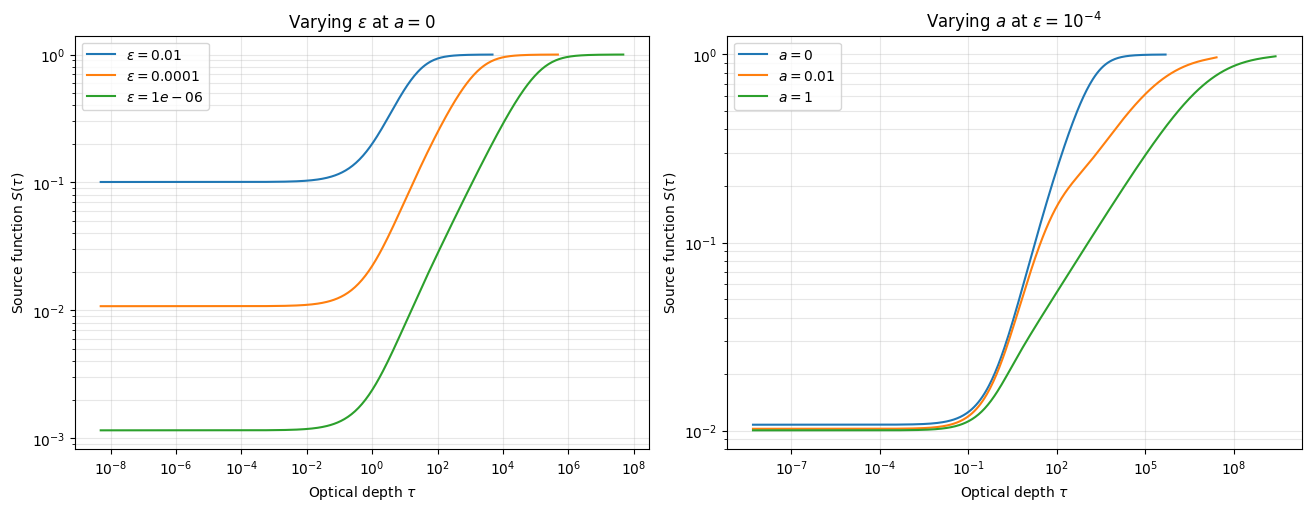

In [4]:
# ------------------------------------------------------------
# Plot log S against log tau
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for eps, (tau, S) in solutions_epsilon.items():
    axes[0].loglog(tau, S, label=rf"$\epsilon={eps:g}$")

axes[0].set_title(rf"Varying $\epsilon$ at $a=0$")
axes[0].set_xlabel(r"Optical depth $\tau$")
axes[0].set_ylabel(r"Source function $S(\tau)$")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

for a, (tau, S) in solutions_a.items():
    axes[1].loglog(tau, S, label=rf"$a={a:g}$")

axes[1].set_title(rf"Varying $a$ at $\epsilon=10^{{-4}}$")
axes[1].set_xlabel(r"Optical depth $\tau$")
axes[1].set_ylabel(r"Source function $S(\tau)$")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend()
plt.show()

In [6]:
import numpy as np
from scipy.special import expn
from scipy.optimize import brentq


def tau_max_for_case(epsilon, a):
    """Use the same lower-boundary choice as in solve_source_function."""
    if a == 0:
        return 50.0 / epsilon
    return max(100.0, 30.0 * 8.0 * a / (9.0 * epsilon**2))


def numerical_thermalization_length(tau, S, B=1.0, level=2/3):
    """
    Find tau where S/B first reaches `level`, then return Lambda = 2*tau.
    Interpolation is linear in log(tau) and S/B.
    """
    ratio = S / B
    crossings = np.flatnonzero(ratio >= level)

    if crossings.size == 0:
        raise ValueError(
            "S/B did not reach 2/3 on this depth grid. "
            "Increase tau_max."
        )

    i = crossings[0]

    if i == 0:
        tau_cross = tau[i]
    else:
        log_tau_cross = np.interp(
            level,
            [ratio[i - 1], ratio[i]],
            np.log([tau[i - 1], tau[i]])
        )
        tau_cross = np.exp(log_tau_cross)

    return 2.0 * tau_cross, tau_cross


def theoretical_thermalization_length(epsilon, a, n_s=1000, nfreq=10001):
    """
    Solve the slide's theoretical criterion:
        K2(Lambda/2) = epsilon

    Uses the same Voigt-profile and frequency conventions as the previous code.
    """
    tau_max = tau_max_for_case(epsilon, a)
    phi, freq_weights = make_profile(a, tau_max, nfreq=nfreq)

    # Search for s = Lambda/2 over a logarithmic grid.
    s_grid = np.geomspace(1e-6, tau_max / 2.0, n_s)

    def K2(s):
        return np.sum(expn(2, s * phi) * phi * freq_weights)

    K2_grid = np.array([K2(s) for s in s_grid])
    below = np.flatnonzero(K2_grid <= epsilon)

    if below.size == 0:
        raise ValueError(
            "K2(s) did not fall below epsilon. Increase tau_max."
        )

    j = below[0]
    if j == 0:
        raise ValueError("Increase the lower end of s_grid.")

    # Root-find in log(s), which is better scaled over a wide range.
    log_s = brentq(
        lambda log_s: K2(np.exp(log_s)) - epsilon,
        np.log(s_grid[j - 1]),
        np.log(s_grid[j]),
    )

    return 2.0 * np.exp(log_s)


def asymptotic_thermalization_length(epsilon, a):
    """
    Far-wing estimates from the slide's K2 asymptotics.

    Doppler: solve Lambda*sqrt[ln(Lambda/(2 sqrt(pi)))] = 1/epsilon
    Voigt wings: Lambda ~= 8a/(9 epsilon^2)
    """
    if a == 0:
        lower = 2.0 * np.sqrt(np.pi) * 1.001
        upper = max(1e4, 100.0 / epsilon**2)

        def equation(log_lambda):
            lam = np.exp(log_lambda)
            log_argument = np.log(lam / (2.0 * np.sqrt(np.pi)))
            return (
                -np.log(lam)
                - 0.5 * np.log(log_argument)
                - np.log(epsilon)
            )

        return np.exp(brentq(equation, np.log(lower), np.log(upper)))

    return 8.0 * a / (9.0 * epsilon**2)


# Collect the five distinct parameter combinations.
cases = [
    (1e-2, 0.0, solutions_epsilon[1e-2]),
    (1e-4, 0.0, solutions_epsilon[1e-4]),
    (1e-6, 0.0, solutions_epsilon[1e-6]),
    (1e-4, 1e-2, solutions_a[1e-2]),
    (1e-4, 1.0, solutions_a[1.0]),
]

print(
    f"{'epsilon':>10} {'a':>8} "
    f"{'Lambda_num':>14} {'Lambda_K2':>14} {'Lambda_asym':>14}"
)

for epsilon, a, (tau, S) in cases:
    lambda_num, tau_23 = numerical_thermalization_length(tau, S)
    lambda_k2 = theoretical_thermalization_length(epsilon, a)
    lambda_asym = asymptotic_thermalization_length(epsilon, a)

    print(
        f"{epsilon:10.1e} {a:8.2g} "
        f"{lambda_num:14.4g} {lambda_k2:14.4g} {lambda_asym:14.4g}"
    )

   epsilon        a     Lambda_num      Lambda_K2    Lambda_asym
   1.0e-02        0          36.45          30.37          59.54
   1.0e-04        0           2252           2016           3787
   1.0e-06        0      1.762e+05      1.611e+05       2.97e+05
   1.0e-04     0.01      3.374e+05      4.808e+05      8.889e+05
   1.0e-04        1      1.467e+07       2.08e+07      8.889e+07


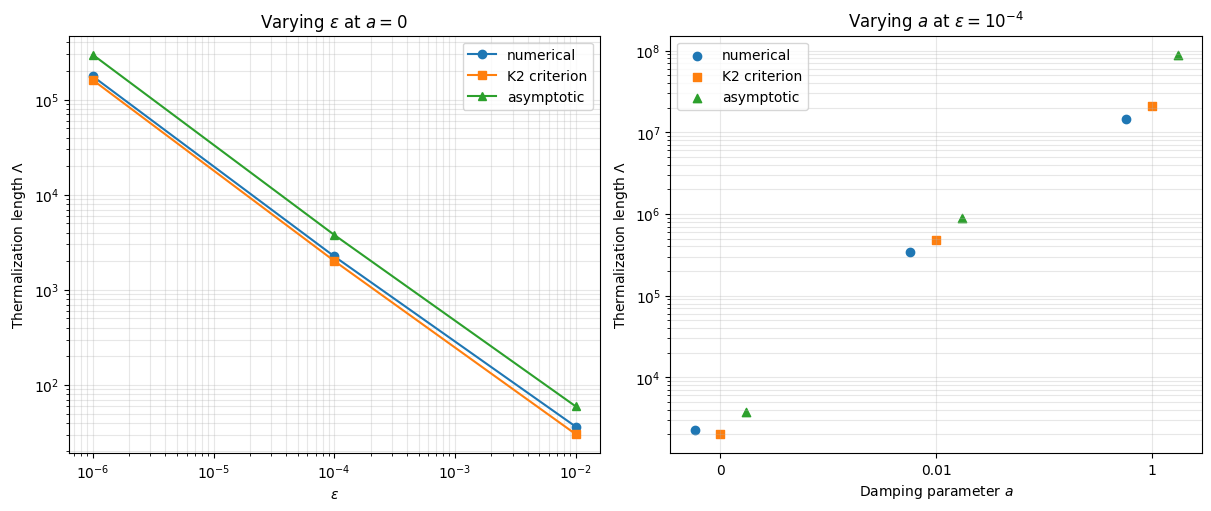

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate the values for the plot from the cases defined above.
records = []

for epsilon, a, (tau, S) in cases:
    lambda_num, _ = numerical_thermalization_length(tau, S)
    lambda_k2 = theoretical_thermalization_length(epsilon, a)
    lambda_asym = asymptotic_thermalization_length(epsilon, a)

    records.append({
        "epsilon": epsilon,
        "a": a,
        "numerical": lambda_num,
        "K2 criterion": lambda_k2,
        "asymptotic": lambda_asym,
    })


fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

# Panel 1: vary epsilon at a = 0
doppler = sorted(
    [r for r in records if r["a"] == 0.0],
    key=lambda r: r["epsilon"]
)

for key, marker in [
    ("numerical", "o"),
    ("K2 criterion", "s"),
    ("asymptotic", "^"),
]:
    axes[0].loglog(
        [r["epsilon"] for r in doppler],
        [r[key] for r in doppler],
        marker=marker,
        label=key,
    )

axes[0].set_xlabel(r"$\epsilon$")
axes[0].set_ylabel(r"Thermalization length $\Lambda$")
axes[0].set_title(r"Varying $\epsilon$ at $a=0$")


# Panel 2: vary damping parameter at epsilon = 1e-4
voigt = sorted(
    [r for r in records if r["epsilon"] == 1e-4],
    key=lambda r: r["a"]
)

x = np.arange(len(voigt))
labels = [f'{r["a"]:g}' for r in voigt]

for key, marker, offset in [
    ("numerical", "o", -0.12),
    ("K2 criterion", "s", 0.0),
    ("asymptotic", "^", 0.12),
]:
    axes[1].scatter(
        x + offset,
        [r[key] for r in voigt],
        marker=marker,
        label=key,
    )

axes[1].set_xticks(x, labels)
axes[1].set_yscale("log")
axes[1].set_xlabel(r"Damping parameter $a$")
axes[1].set_ylabel(r"Thermalization length $\Lambda$")
axes[1].set_title(r"Varying $a$ at $\epsilon=10^{-4}$")

for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

plt.show()

   epsilon        a     S(0) numerical    sqrt(epsilon) B      ratio
   1.0e-02        0             0.1008                0.1     1.0080
   1.0e-04        0          0.0107771               0.01     1.0777
   1.0e-06        0         0.00115344              0.001     1.1534
   1.0e-04     0.01          0.0102542               0.01     1.0254
   1.0e-04        1          0.0100607               0.01     1.0061


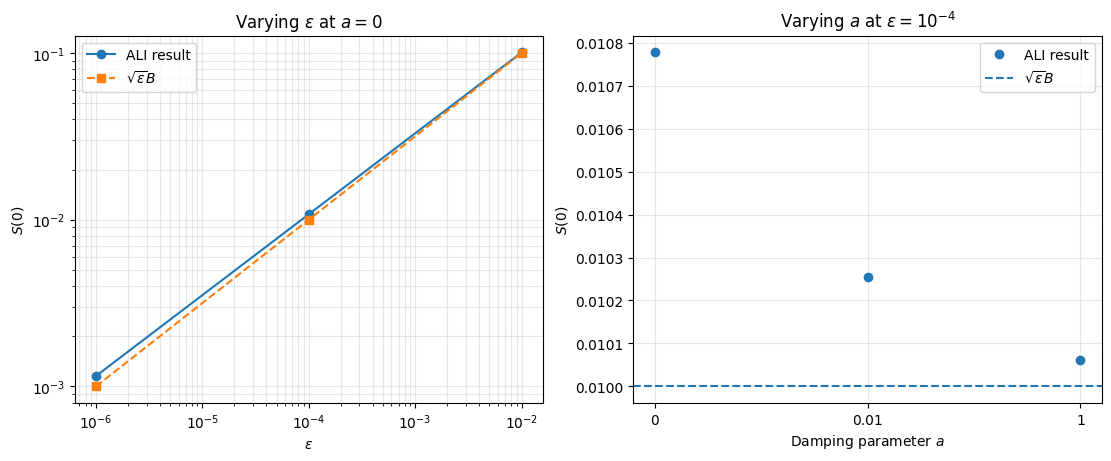

In [8]:
import numpy as np
import matplotlib.pyplot as plt

B = 1.0
tmin = 1e-8
points_per_decade = 28

def surface_source_function(epsilon, a, S):
    """Evaluate S(0) from the surface integral equation."""
    tau_max = tau_max_for_case(epsilon, a)

    n_log = int(np.ceil(
        points_per_decade * np.log10(tau_max / tmin)
    ))
    positive_edges = np.geomspace(tmin, tau_max, n_log + 1)
    edges = np.concatenate(([0.0], positive_edges))

    # Match the kernel resolution used in the previous solver.
    centers = 0.5 * (edges[:-1] + edges[1:])
    distances = np.concatenate((
        centers - edges[:-1],
        edges[1:] - centers
    ))
    min_s = max(np.min(distances[distances > 0]) * 0.05, 1e-14)

    F, K2 = make_F_interpolator(
        a=a,
        tau_max=tau_max,
        min_s=min_s,
        nfreq=10001,
    )

    # Integral of K1(tau') over each depth cell:
    # integral_left^right K1(tau') d tau' = F(right) - F(left)
    cell_weights = F(edges[1:]) - F(edges[:-1])

    # Approximate the omitted semi-infinite tail with S = B.
    tail_weight = 0.5 * float(K2(np.array([tau_max]))[0])

    return (
        (1.0 - epsilon)
        * (np.dot(cell_weights, S) + tail_weight * B)
        + epsilon * B
    )


# Use the cases and ALI solutions from the previous parts.
surface_results = []

for epsilon, a, (tau, S) in cases:
    S0_num = surface_source_function(epsilon, a, S)
    S0_theory = np.sqrt(epsilon) * B

    surface_results.append({
        "epsilon": epsilon,
        "a": a,
        "numerical": S0_num,
        "theory": S0_theory,
    })

print(f"{'epsilon':>10} {'a':>8} {'S(0) numerical':>18} "
      f"{'sqrt(epsilon) B':>18} {'ratio':>10}")

for r in surface_results:
    print(
        f"{r['epsilon']:10.1e} {r['a']:8.2g} "
        f"{r['numerical']:18.6g} {r['theory']:18.6g} "
        f"{r['numerical'] / r['theory']:10.4f}"
    )


# Plot: varying epsilon at a=0, and varying a at epsilon=1e-4
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

doppler = sorted(
    [r for r in surface_results if r["a"] == 0.0],
    key=lambda r: r["epsilon"]
)

axes[0].loglog(
    [r["epsilon"] for r in doppler],
    [r["numerical"] for r in doppler],
    "o-",
    label="ALI result",
)
axes[0].loglog(
    [r["epsilon"] for r in doppler],
    [r["theory"] for r in doppler],
    "s--",
    label=r"$\sqrt{\epsilon}B$",
)
axes[0].set_xlabel(r"$\epsilon$")
axes[0].set_ylabel(r"$S(0)$")
axes[0].set_title(r"Varying $\epsilon$ at $a=0$")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

damping_cases = sorted(
    [r for r in surface_results if r["epsilon"] == 1e-4],
    key=lambda r: r["a"]
)
x = np.arange(len(damping_cases))

axes[1].plot(
    x,
    [r["numerical"] for r in damping_cases],
    "o",
    label="ALI result",
)
axes[1].axhline(
    np.sqrt(1e-4) * B,
    linestyle="--",
    label=r"$\sqrt{\epsilon}B$",
)
axes[1].set_xticks(x, [f'{r["a"]:g}' for r in damping_cases])
axes[1].set_xlabel(r"Damping parameter $a$")
axes[1].set_ylabel(r"$S(0)$")
axes[1].set_title(r"Varying $a$ at $\epsilon=10^{-4}$")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.show()